In [2]:
from scipy.signal import find_peaks, savgol_filter
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
plt.close()
import matplotlib as mpl
from matplotlib import gridspec

from brokenaxes import brokenaxes

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
import os
import pickle5 as pickle
import csv
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

import import_ipynb
import ipynb.fs.full.ssiProjectModule2 as ssiMod

from tqdm.notebook import tqdm
import sys

import importlib as imp
imp.reload(ssiMod)

from scipy.stats import wilcoxon as w
from scipy.special import factorial
from scipy.stats import circmean
from scipy.stats import circstd
import math
import statsmodels.stats.api as sms

from multiprocessing import Pool
from functools import partial

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from datetime import datetime
import bisect


output_dir = '/home/cparis/00PhD/DS_PCBreview/'



theta_step = 2
main_dir = '/home/cparis/00PhD/'

area_or_max = 'Area'
dat_dir_out = main_dir + f'Simulated Stretch/Analyze stretched quadruplets constrained by AREA or MAX/'

title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'
# title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240506_MAX.pkl'


with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)
print(data_dict.keys())


stim = np.arange(0,360,theta_step)

example = 201
bio_idx = np.where(data_dict['all_multipliers']==1)[0][0]
example_quad_pars = data_dict['all_quad_pars'][example,bio_idx]
example_quad_tc = np.array([ssiMod.FTVM_dx(stim, *pars) for pars in example_quad_pars])

/home/cparis/anaconda3/lib/python3.7/site-packages/statsmodels/compat/pandas.py:49: FutureWarning: The Panel class is removed from pandas. Accessing it from the top-level namespace will also be removed in the next version
  data_klasses = (pandas.Series, pandas.DataFrame, pandas.Panel)


dict_keys(['all_multipliers', 'all_quad_pars', 'all_quad_tc', 'all_ssis', 'all_quad_fwhm', 'exp_quad_list', 'all_quad_vm_fit_pars', 'all_quad_raw_mean_tcs', 'all_quad_raw_mean_stds', 'original_cell_idx_quads'])


In [3]:
main_dir = '/home/cparis/00PhD/'


quad_list = []

#array labelling the biological quadruplets
bio_quad_idx = []

for experiment_number in range(1,8,1):
    experiment_name = f'Exp{experiment_number}'
    datanfits = dict(np.load(main_dir+f'Analysis of {experiment_name}.npz'))
    print(datanfits['quadruplet_combos'].shape)
    quad_list += zip(np.full(len(datanfits['quadruplet_combos']), experiment_number), datanfits['quadruplet_combos'])
#     for each quadruplet
    for quad in datanfits['quadruplet_combos']:
        if quad.tolist() in datanfits['biological_quadruplets'].tolist():
            bio_quad_idx += [True]
        else:  bio_quad_idx+= [False]
bio_quad_idx = np.array(bio_quad_idx)    

data_dict['exp_quad_list'] = quad_list

exp_idx, quad = zip(*data_dict['exp_quad_list'])
quad = np.array(quad)
print('Number of bio quads in:')
for experiment_number in range(1,8,1):
    q = np.count_nonzero(np.array(exp_idx)[bio_quad_idx]==experiment_number)
    print(f'Experiment {experiment_number}: {q}',)

(120, 4)
(18, 4)
(72, 4)
(24, 4)
(160, 4)
(250, 4)
(4, 4)
Number of bio quads in:
Experiment 1: 21
Experiment 2: 0
Experiment 3: 9
Experiment 4: 0
Experiment 5: 33
Experiment 6: 19
Experiment 7: 2


In [4]:
non_prox_idx = np.arange(0,len(bio_quad_idx))[np.logical_not(bio_quad_idx)]

idx_sample = np.array([np.random.choice(non_prox_idx, np.count_nonzero(bio_quad_idx), replace=False) for _ in range(100)])
print(idx_sample.shape)

peaks_min = [find_peaks(savgol_filter(quad_ssi.min(axis=1), \
                                      window_length=3, \
                                      polyorder=0)[np.where(data_dict['all_quad_fwhm'].mean(axis=2)[i]<=180)], \
                        distance = 5, prominence=0.05)[0] for i,quad_ssi in enumerate(data_dict['all_ssis'])]


bio_peaks_min = [x for x, b in zip(peaks_min, bio_quad_idx) if b]
bio_lengths = [len(x) for x in bio_peaks_min]
bio_counts = Counter(bio_lengths)
bio_fractions = np.array([np.around(bio_counts.get(k,0)/len(bio_peaks_min),3) for k in [1,2,3]])
print(bio_fractions)


lengths = np.array([np.array([len(peaks_min[i]) for i in idx_sample_row]) for idx_sample_row in idx_sample])

fractions = np.array([np.array([np.around(Counter(lengths_row).get(k,0)/len(lengths_row),3) for k in [1,2,3]]) \
                      for lengths_row in lengths])


(100, 84)


/home/cparis/anaconda3/lib/python3.7/site-packages/scipy/signal/_arraytools.py:45: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  b = a[a_slice]


[0.536 0.464 0.   ]


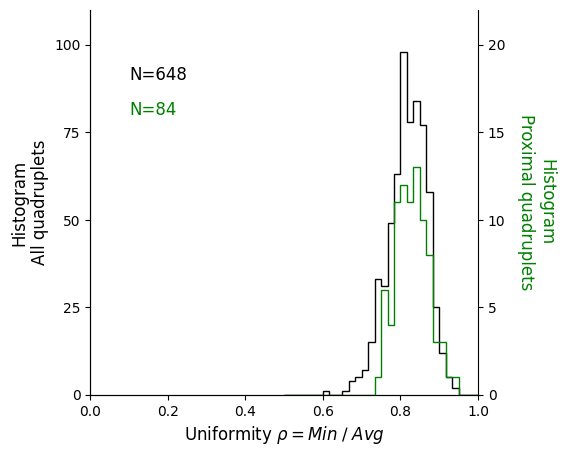

In [5]:
fig = plt.figure(figsize = (5,5))
ax1 = fig.add_subplot(111)
mpl.rcParams['axes.spines.right']=True
ax2 = ax1.twinx()

ro = data_dict['all_ssis'].min(axis=2)[:,bio_idx]/data_dict['all_ssis'].mean(axis=2)[:,bio_idx]
example_quads = [125,201]

ax1.hist(ro, \
         color = 'k',bins = 30, range=(0.5,1), histtype = 'step')
ax2.hist(ro[bio_quad_idx], \
         color = 'green', bins = 30, range=(0.5,1), histtype = 'step')
# ax1.scatter(ro[example_quads],[105,105], color = 'magenta', s=10)

ax1.set_xlim(0,1)
ax1.set_xticks(np.arange(0,1.1, 0.2))
ax1.set_xlabel(r'Uniformity $\rho= Min\;\slash\;Avg$', size = 12)
ax1.set_ylim(0,110)
ax1.set_yticks(np.arange(0,101, 25))
ax1.set_ylabel('Histogram\nAll quadruplets', color = 'k', size = 12)
ax2.set_ylim(0,22)
ax2.set_yticks(np.arange(0,21,5))
ax2.set_ylabel('Histogram\nProximal quadruplets', rotation=270, color = 'green', size = 12)
ax2.yaxis.set_label_coords(1.2, 0.5)
ax1.text(0.1, 90, 'N=648', size =12, c='k')
ax1.text(0.1, 80, 'N=84', size =12, c='g')
mpl.rcParams['axes.spines.right']=False

# fig.savefig('/home/cparis/Desktop/Uniformity_all_v_bio.jpg', bbox_inches = 'tight', dpi=300)

[352.92024 282.25584  12.97944]


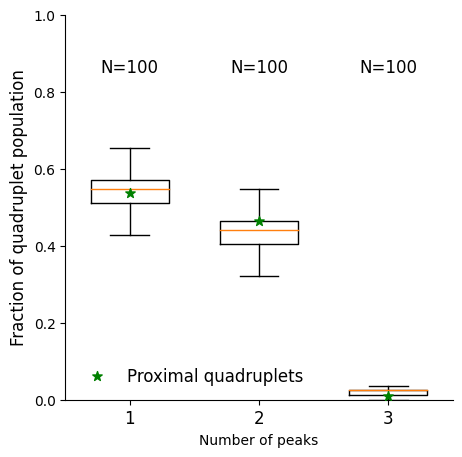

In [18]:
fig, ax = plt.subplots(figsize = (5,5))

data = np.copy(fractions)
cond1, cond2,cond3 = data[:,0], data[:,1], data[:,2]


# Boxplot
ax.boxplot(data, positions=[1, 2, 3], widths=0.6, showfliers=False)

for k in [0,1,2]:
    if k==2:
        add=0.01
    else: add=0
    if k==0: 
        label='Proximal quadruplets'
    else: label ='__nolegend__'

    ax.scatter(k+1, bio_fractions[k]+add, color = 'green', marker='*', zorder = 10, s=50, label = label)
# Means
means = fractions.mean(axis=0)


for i,el in enumerate([cond1, cond2, cond3]):
    ax.text(i+1, 0.85, f'N={len(el)}', size = 12, ha='center')

# Errorbars (SEM here)
errors = fractions.std(axis=0)

# ax.errorbar(
#     [1, 2, 3], means,
#     yerr=errors,
#     fmt='v',
#     color='red',
#     capsize=5,
#     label='Mean ± SEM'
# )

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['1', '2', '3'], size = 12)
ax.set_xlabel('Number of peaks')

ax.set_ylabel(f'Fraction of quadruplet population', size = 12)
ax.set_ylim(0,1)
ax.legend(frameon=0, fontsize = 12, loc = 'lower left')

fig.savefig(output_dir+'')

print(means*648)

0.10758377425044091 0.33740040098219437


/home/cparis/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:80: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


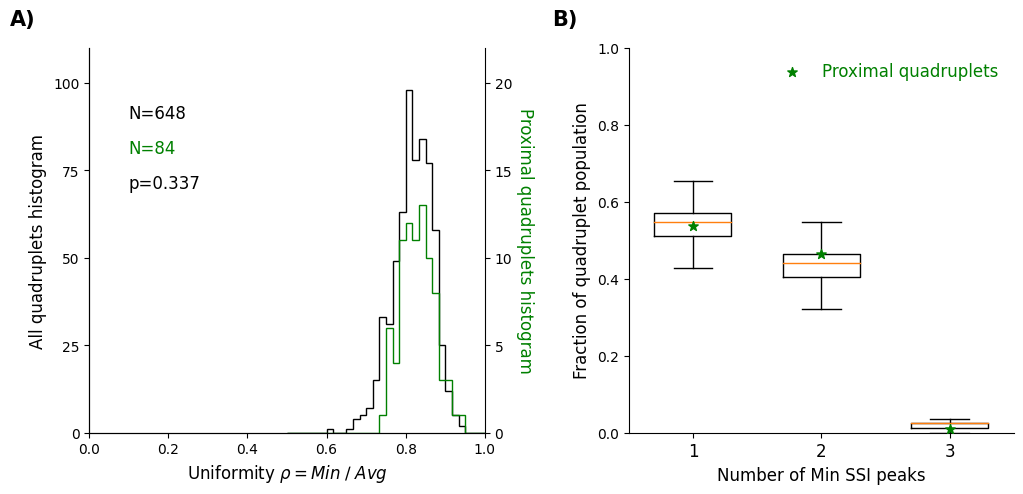

In [24]:
from scipy.stats import ks_2samp

fig = plt.figure(figsize=(12,5))
gs = fig.add_gridspec(1, 2, wspace=0.35)

# -----------------------
# Panel 1: Histogram
# -----------------------
ax1 = fig.add_subplot(gs[0,0])
ax1.set_box_aspect(1)
mpl.rcParams['axes.spines.right'] = True

ax2 = ax1.twinx()

ro = data_dict['all_ssis'].min(axis=2)[:,bio_idx] / data_dict['all_ssis'].mean(axis=2)[:,bio_idx]
stat, p = ks_2samp(ro[np.logical_not(bio_quad_idx)], ro[bio_quad_idx])



ax1.hist(ro, color='k', bins=30, range=(0.5,1), histtype='step')
ax2.hist(ro[bio_quad_idx], color='green', bins=30, range=(0.5,1), histtype='step')

ax1.set_xlim(0,1)
ax1.set_xticks(np.arange(0,1.1,0.2))
ax1.set_xlabel(r'Uniformity $\rho= Min\;\slash\;Avg$', size=12)

ax1.set_ylim(0,110)
ax1.set_yticks(np.arange(0,101,25))
ax1.set_ylabel('All quadruplets histogram', color='k', size=12)

ax2.set_ylim(0,22)
ax2.set_yticks(np.arange(0,21,5))
ax2.set_ylabel('Proximal quadruplets histogram', rotation=270, color='green', size=12)
ax2.yaxis.set_label_coords(1.125,0.5)

ax1.text(0.1,90,'N=648', size=12, c='k')
ax1.text(0.1,80,'N=84', size=12, c='g')
ax1.text(0.1,70,f'p={p:.3f}', size=12, c='k')


mpl.rcParams['axes.spines.right'] = False
ax1.text(-0.2, 1.1, 'A)', ha='left', va='top', transform=ax1.transAxes, fontweight='bold', fontsize = 15)




print(stat, p)
# -----------------------
# Panel 2: Boxplot
# -----------------------
ax = fig.add_subplot(gs[0,1])
ax.set_box_aspect(1)

data = np.copy(fractions)

ax.boxplot(data, positions=[1,2,3], widths=0.6, showfliers=False)

for k in [0,1,2]:
    add = 0.01 if k==2 else 0
    label = 'Proximal quadruplets' if k==0 else '__nolegend__'
    
    ax.scatter(k+1, bio_fractions[k]+add,
               color='green', marker='*',
               zorder=10, s=50, label=label)
    
ax.set_xticks([1,2,3])
ax.set_xticklabels(['1', '2', '3'], size = 12)
ax.set_xlabel('Number of Min SSI peaks', size =12)

ax.set_ylabel('Fraction of quadruplet population', size=12)
ax.set_ylim(0,1)

ax.legend(frameon=0, fontsize=12, labelcolor = 'green', loc = 'upper right')
ax.text(-0.2, 1.1, 'B)', ha='left', va='top', transform=ax.transAxes, fontweight='bold', fontsize = 15)

plt.tight_layout()
fig.savefig(output_dir+'ProximalRFs_results.jpg', dpi=300, bbox_inches="tight")


In [113]:
bio_fractions

array([0.536, 0.464, 0.   ])